# 03 · Análisis bivariado y perfilado automático

En este notebook comparamos la tenencia de tarjeta con cinco variables: `edad_1998`, `antiguedad_cuenta_anios`, `num_transacciones`, `saldo_promedio` y `frecuencia`.

En `tiene_tarjeta`, el valor 1 indica que el cliente tiene una tarjeta registrada y el 0 indica que no. Esto no nos dice si el cliente es apto para recibir crédito.

Primero necesitamos ejecutar el notebook 01. Para generar el informe HTML, también debemos tener instalado `ydata-profiling` en el entorno de Jupyter.

## 1. Librerías y rutas

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')

def localizar_proyecto():
    # Funciona al abrir Jupyter desde la carpeta principal o desde notebooks/.
    for ruta in [Path.cwd(), *Path.cwd().parents]:
        if (ruta / 'datos' / 'Caso Berka.zip').is_file():
            return ruta
    raise FileNotFoundError(
        'No se encontró datos/Caso Berka.zip. Abre Jupyter desde Berka_Equipo/.'
    )

RAIZ = localizar_proyecto()
INTERMEDIOS = RAIZ / 'intermedios'
RESULTADOS = RAIZ / 'resultados'
GRAFICOS = RESULTADOS / 'graficos'
for carpeta in [INTERMEDIOS, RESULTADOS, GRAFICOS]:
    carpeta.mkdir(parents=True, exist_ok=True)
print('Proyecto:', RAIZ.resolve())

Proyecto: /mnt/data/Berka_Equipo


## 2. Cargar el dataframe integrado e identificar Y

In [2]:
ruta = INTERMEDIOS / '01_base_clientes.csv'
if not ruta.is_file():
    raise FileNotFoundError('Ejecuta primero el notebook 01.')
df = pd.read_csv(ruta)
assert df['client_id'].is_unique
assert set(df['tiene_tarjeta'].dropna().unique()) <= {0,1}
print('Distribución de la variable respuesta (Y):')
print(df['tiene_tarjeta'].value_counts())
print('Tasa de tenencia:',round(100*df['tiene_tarjeta'].mean(),2),'%')

Distribución de la variable respuesta (Y):
tiene_tarjeta
0    4477
1     892
Name: count, dtype: int64
Tasa de tenencia: 16.61 %


## 3. Análisis bivariado de cuatro variables numéricas

edad_1998                      antiguedad_cuenta_anios        \
                  count   mean median    std                   count  mean   
tiene_tarjeta                                                                
0                  4477  45.95   45.0  17.57                    4477  3.40   
1                   892  39.06   39.0  14.45                     892  3.41   

                           num_transacciones                         \
              median   std             count    mean median     std   
tiene_tarjeta                                                         
0               2.98  1.53              4477  232.45  205.0  127.41   
1               3.05  1.48               892  248.81  225.0  128.22   

              saldo_promedio                                
                       count      mean    median       std  
tiene_tarjeta                                               
0                       4477  33450.81  30904.68  14108.33  
1                        892  51653.26  51291.95  11109.34

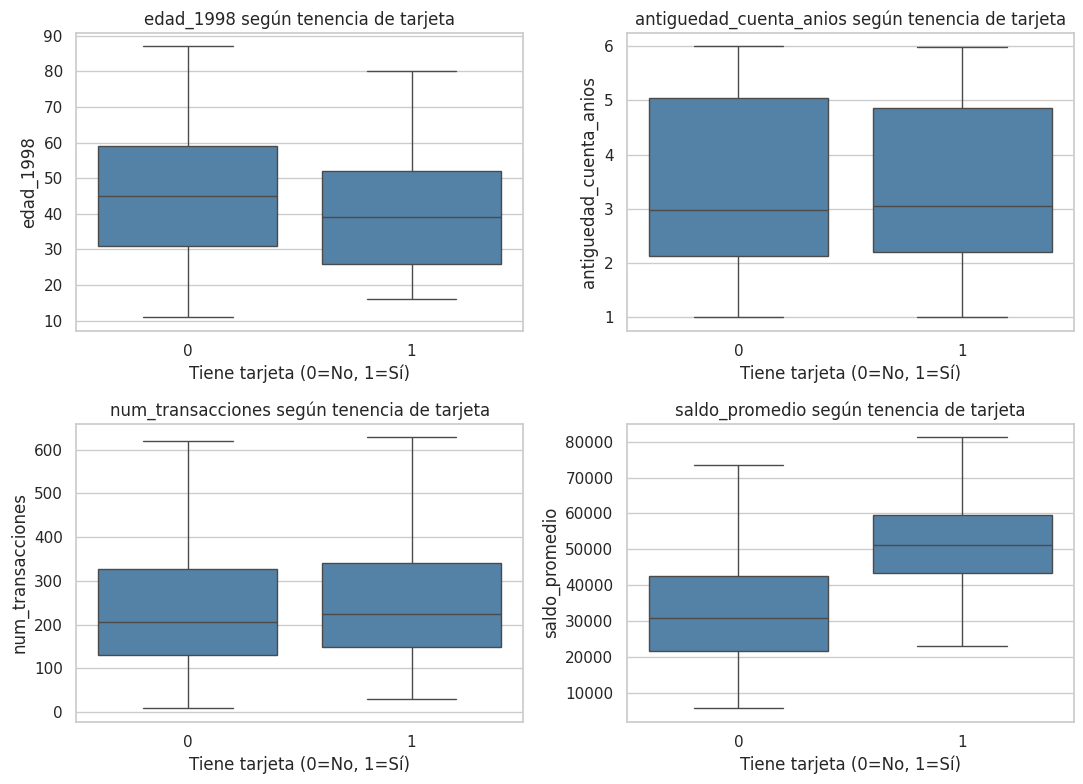

In [3]:
VARIABLES_NUM = ['edad_1998','antiguedad_cuenta_anios',
                 'num_transacciones','saldo_promedio']
resumen_num = df.groupby('tiene_tarjeta')[VARIABLES_NUM].agg(
    ['count','mean','median','std'])
display(resumen_num.round(2))
resumen_num.to_csv(RESULTADOS/'03_bivariado_numericas.csv',encoding='utf-8-sig')

fig,ejes=plt.subplots(2,2,figsize=(11,8))
for ax,var in zip(ejes.flat,VARIABLES_NUM):
    sns.boxplot(data=df,x='tiene_tarjeta',y=var,ax=ax,showfliers=False,color='steelblue')
    ax.set_title(f'{var} según tenencia de tarjeta')
    ax.set_xlabel('Tiene tarjeta (0=No, 1=Sí)')
fig.tight_layout()
fig.savefig(GRAFICOS/'03_bivariado_numericas.png',dpi=150)
plt.show()
plt.close(fig)

## 4. Quinta variable: `frecuencia` (cualitativa)
Comparamos el porcentaje de clientes con tarjeta en cada grupo de frecuencia, ya que los grupos tienen tamaños distintos.

,clientes,clientes_con_tarjeta,tasa,tasa_pct
frecuencia,,,,
POPLATEK TYDNE,282,66,0.23,23.40
POPLATEK PO OBRATU,107,20,0.19,18.69
POPLATEK MESICNE,4980,806,0.16,16.18


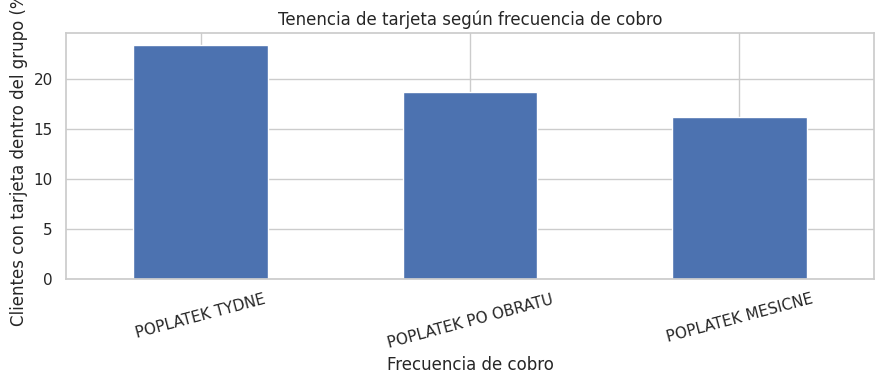

In [4]:
resumen_frec = (
    df.groupby('frecuencia',dropna=False)['tiene_tarjeta']
    .agg(clientes='size', clientes_con_tarjeta='sum', tasa='mean')
    .sort_values('tasa',ascending=False))
resumen_frec['tasa_pct']=100*resumen_frec['tasa']
display(resumen_frec.round(2))
resumen_frec.to_csv(RESULTADOS/'03_bivariado_frecuencia.csv',encoding='utf-8-sig')

fig,ax=plt.subplots(figsize=(9,4))
resumen_frec['tasa_pct'].plot.bar(ax=ax)
ax.set_ylabel('Clientes con tarjeta dentro del grupo (%)')
ax.set_xlabel('Frecuencia de cobro')
ax.set_title('Tenencia de tarjeta según frecuencia de cobro')
ax.tick_params(axis='x',rotation=15)
fig.tight_layout()
fig.savefig(GRAFICOS/'03_bivariado_frecuencia.png',dpi=150)
plt.show()
plt.close(fig)

## 5. Perfilado con `ydata_profiling`
Revisamos las variables seleccionadas antes de transformarlas e incluimos `tiene_tarjeta` para ver su distribución. Dejamos fuera los identificadores, `n_tarjetas` y `fecha_primera_tarjeta`, porque las dos últimas revelan directamente la respuesta.

Si falta la librería, podemos instalarla con `python -m pip install ydata-profiling` en el entorno activo. Después reiniciamos el kernel y volvemos a ejecutar el notebook.

In [5]:
NUMERICAS_MODELO = ['edad_1998','antiguedad_cuenta_anios',
    'num_transacciones','importe_ingresos','importe_egresos',
    'importe_medio_transaccion','saldo_promedio']
CATEGORICAS_MODELO = ['tipo_disposicion','frecuencia']
columnas_perfil = NUMERICAS_MODELO+CATEGORICAS_MODELO+['tiene_tarjeta']
assert len(columnas_perfil)==len(set(columnas_perfil))

# Avisamos si falta la librería para generar el informe.
try:
    from ydata_profiling import ProfileReport
except ImportError:
    print('PERFILADO PENDIENTE: instalar ydata-profiling en este kernel.')
    print('Comando: python -m pip install ydata-profiling')
    (RESULTADOS/'03_perfilado_pendiente.txt').write_text(
        'Falta ejecutar ProfileReport con ydata-profiling en el entorno del equipo.\n',
        encoding='utf-8')
else:
    perfil = ProfileReport(df[columnas_perfil], title='Banco Berka: perfilado del modelo',
                           minimal=True, explorative=True)
    destino = RESULTADOS/'03_perfilado_ydata.html'
    perfil.to_file(str(destino))
    (RESULTADOS/'03_perfilado_pendiente.txt').unlink(missing_ok=True)
    print('Perfilado creado:',destino)

PERFILADO PENDIENTE: instalar ydata-profiling en este kernel.
Comando: python -m pip install ydata-profiling


## 6. Interpretar y responder el entendimiento de datos
Al interpretar los resultados, debemos considerar que algunas cuentas son compartidas y que ciertos movimientos pueden ser posteriores a la emisión de la tarjeta.

Los gráficos y el perfilado nos ayudan a describir los datos y comparar los grupos. Las diferencias observadas no prueban que una variable cause la tenencia de tarjeta.

In [6]:
print('Resumen de diferencias entre grupos (medias):')
for var in VARIABLES_NUM:
    media = df.groupby('tiene_tarjeta')[var].mean()
    print(f'{var}: Y=0 {media.get(0,float("nan")):.2f} / Y=1 {media.get(1,float("nan")):.2f}')
print('Nota: diferencia descriptiva; no constituye causalidad.')

Resumen de diferencias entre grupos (medias):
edad_1998: Y=0 45.95 / Y=1 39.06
antiguedad_cuenta_anios: Y=0 3.40 / Y=1 3.41
num_transacciones: Y=0 232.45 / Y=1 248.81
saldo_promedio: Y=0 33450.81 / Y=1 51653.26
Nota: diferencia descriptiva; no constituye causalidad.
